
# Food.com Recipe Ranking System
## 01 – Data Exploration

### 1. Introduction

This notebook explores the original Food.com Recipes and User Interactions datasets.

The purpose of this stage is to understand the structure, characteristics, and quality of the datasets before performing data cleaning, preprocessing, exploratory data analysis, and recipe ranking.

### 2. Dataset Description

This project uses two datasets:

**1. Recipes Dataset**
- Contains recipe information such as recipe names, cooking time, ingredients, instructions, nutrition, and submission dates.
- Each recipe is identified by a unique recipe ID.

**2. User Interactions Dataset**
- Contains user ratings and reviews for recipes.
- Connects users with recipes through user IDs and recipe IDs.

### 3. Objectives

- Understand dataset dimensions and structure.
- Examine column names and data types.
- Inspect sample records.
- Identify missing values and duplicate records.
- Explore numerical variables.
- Understand how the two datasets can be connected using recipe IDs.

### 4. Important Note

The original datasets will remain unchanged. All cleaning and preprocessing operations will be performed separately in later stages.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Define the paths to the original datasets
recipes_path = "../data/raw/RAW_recipes.csv"
interactions_path = "../data/raw/RAW_interactions.csv"

# Load the datasets into Pandas DataFrames
recipes_df = pd.read_csv(recipes_path)
interactions_df = pd.read_csv(interactions_path)

print("Both datasets loaded successfully!")


Both datasets loaded successfully!


In [3]:

# Display the dimensions of both datasets

print("RECIPES DATASET")
print("-" * 40)
print("Number of rows:", recipes_df.shape[0])
print("Number of columns:", recipes_df.shape[1])

print("\nUSER INTERACTIONS DATASET")
print("-" * 40)
print("Number of rows:", interactions_df.shape[0])
print("Number of columns:", interactions_df.shape[1])


RECIPES DATASET
----------------------------------------
Number of rows: 231637
Number of columns: 12

USER INTERACTIONS DATASET
----------------------------------------
Number of rows: 1132367
Number of columns: 5


In [4]:

# Display the first five records from the recipes dataset

print("SAMPLE RECORDS - RECIPES DATASET")
display(recipes_df.head())

# Display the first five records from the interactions dataset

print("\nSAMPLE RECORDS - USER INTERACTIONS DATASET")
display(interactions_df.head())


SAMPLE RECORDS - RECIPES DATASET


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8



SAMPLE RECORDS - USER INTERACTIONS DATASET


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [5]:

# Display column names in the recipes dataset

print("RECIPES DATASET COLUMNS")
print("-" * 40)

for column in recipes_df.columns:
    print(column)

# Display column names in the interactions dataset

print("\nUSER INTERACTIONS DATASET COLUMNS")
print("-" * 40)

for column in interactions_df.columns:
    print(column)


RECIPES DATASET COLUMNS
----------------------------------------
name
id
minutes
contributor_id
submitted
tags
nutrition
n_steps
steps
description
ingredients
n_ingredients

USER INTERACTIONS DATASET COLUMNS
----------------------------------------
user_id
recipe_id
date
rating
review


In [6]:

# Display data types of the recipes dataset

print("RECIPES DATASET - DATA TYPES")
print("-" * 45)
print(recipes_df.dtypes)

# Display data types of the interactions dataset

print("\nUSER INTERACTIONS DATASET - DATA TYPES")
print("-" * 45)
print(interactions_df.dtypes)


RECIPES DATASET - DATA TYPES
---------------------------------------------
name                str
id                int64
minutes           int64
contributor_id    int64
submitted           str
tags                str
nutrition           str
n_steps           int64
steps               str
description         str
ingredients         str
n_ingredients     int64
dtype: object

USER INTERACTIONS DATASET - DATA TYPES
---------------------------------------------
user_id      int64
recipe_id    int64
date           str
rating       int64
review         str
dtype: object


In [7]:

# Count missing values in the recipes dataset

print("RECIPES DATASET - MISSING VALUES")
print("-" * 45)
print(recipes_df.isnull().sum())

# Count missing values in the interactions dataset

print("\nUSER INTERACTIONS DATASET - MISSING VALUES")
print("-" * 45)
print(interactions_df.isnull().sum())


RECIPES DATASET - MISSING VALUES
---------------------------------------------
name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

USER INTERACTIONS DATASET - MISSING VALUES
---------------------------------------------
user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64


In [8]:

# Calculate missing-value percentages for recipes

recipes_missing = pd.DataFrame({
    "Missing Values": recipes_df.isnull().sum(),
    "Missing Percentage": (recipes_df.isnull().sum() / len(recipes_df)) * 100
})

print("RECIPES DATASET - MISSING VALUE SUMMARY")
print("-" * 55)
display(recipes_missing[recipes_missing["Missing Values"] > 0].round(2))


# Calculate missing-value percentages for interactions

interactions_missing = pd.DataFrame({
    "Missing Values": interactions_df.isnull().sum(),
    "Missing Percentage": (interactions_df.isnull().sum() / len(interactions_df)) * 100
})

print("\nUSER INTERACTIONS DATASET - MISSING VALUE SUMMARY")
print("-" * 55)
display(interactions_missing[interactions_missing["Missing Values"] > 0].round(2))


RECIPES DATASET - MISSING VALUE SUMMARY
-------------------------------------------------------


,Missing Values,Missing Percentage
name,1,0.00
description,4979,2.15



USER INTERACTIONS DATASET - MISSING VALUE SUMMARY
-------------------------------------------------------


,Missing Values,Missing Percentage
review,169,0.01



### Missing Value Analysis – Initial Findings

The missing-value analysis identified the following:

**Recipes Dataset**
- One record has a missing recipe name.
- 4,979 records (2.15%) have missing descriptions.
- The record with the missing recipe name will be removed during preprocessing because recipe names are important for displaying and identifying recipes.
- Missing descriptions will be retained because descriptions are not essential for calculating recipe rankings.

**User Interactions Dataset**
- 169 records (0.01%) have missing written reviews.
- These records will be retained because numerical ratings are available independently of written reviews.

**Conclusion:**

The proportion of missing values is very small in both datasets. Most missing values do not prevent us from using the records for recipe analysis and ranking.


In [9]:

# Check exact duplicate records in the recipes dataset

recipes_duplicates = recipes_df.duplicated().sum()

print("RECIPES DATASET")
print("-" * 40)
print("Number of duplicate rows:", recipes_duplicates)


# Check exact duplicate records in the interactions dataset

interactions_duplicates = interactions_df.duplicated().sum()

print("\nUSER INTERACTIONS DATASET")
print("-" * 40)
print("Number of duplicate rows:", interactions_duplicates)


RECIPES DATASET
----------------------------------------
Number of duplicate rows: 0

USER INTERACTIONS DATASET
----------------------------------------
Number of duplicate rows: 0


RECIPES DATASET
----------------------------------------
Number of duplicate rows: 0

USER INTERACTIONS DATASET
----------------------------------------
Number of duplicate rows: 0

In [10]:

# Generate descriptive statistics for numerical columns in recipes

print("RECIPES DATASET - NUMERICAL SUMMARY")
print("-" * 55)

display(recipes_df.describe())


RECIPES DATASET - NUMERICAL SUMMARY
-------------------------------------------------------


,id,minutes,contributor_id,n_steps,n_ingredients
count,231637.000000,2.316370e+05,2.316370e+05,231637.000000,231637.000000
mean,222014.708984,9.398546e+03,5.534885e+06,9.765499,9.051153
std,141206.635626,4.461963e+06,9.979141e+07,5.995128,3.734796
min,38.000000,0.000000e+00,2.700000e+01,0.000000,1.000000
25%,99944.000000,2.000000e+01,5.690500e+04,6.000000,6.000000
50%,207249.000000,4.000000e+01,1.736140e+05,9.000000,9.000000
75%,333816.000000,6.500000e+01,3.982750e+05,12.000000,11.000000
max,537716.000000,2.147484e+09,2.002290e+09,145.000000,43.000000



### Numerical Summary – Recipes Dataset

The descriptive statistics reveal the following characteristics:

1. **Cooking Time:** The median cooking time is 40 minutes, while the mean is approximately 9,399 minutes. The extremely high maximum value indicates unusual cooking-time observations that require further investigation.

2. **Preparation Steps:** Recipes contain an average of approximately 10 preparation steps, with a median of 9. The dataset includes a recipe with zero steps and a maximum of 145 steps.

3. **Number of Ingredients:** Recipes contain an average of approximately 9 ingredients, with a median of 9 and a maximum of 43 ingredients.

**Conclusion:**

The cooking-time variable contains extreme values that may affect statistical analysis. These observations will be investigated during exploratory data analysis and preprocessing.


In [11]:

# Generate descriptive statistics for numerical columns in interactions

print("USER INTERACTIONS DATASET - NUMERICAL SUMMARY")
print("-" * 55)

display(interactions_df.describe())


USER INTERACTIONS DATASET - NUMERICAL SUMMARY
-------------------------------------------------------


,user_id,recipe_id,rating
count,1.132367e+06,1.132367e+06,1.132367e+06
mean,1.384291e+08,1.608972e+05,4.411016e+00
std,5.014269e+08,1.303987e+05,1.264752e+00
min,1.533000e+03,3.800000e+01,0.000000e+00
25%,1.354700e+05,5.425700e+04,4.000000e+00
50%,3.309370e+05,1.205470e+05,5.000000e+00
75%,8.045500e+05,2.438520e+05,5.000000e+00
max,2.002373e+09,5.377160e+05,5.000000e+00



### Numerical Summary – User Interactions Dataset

The descriptive statistics reveal the following characteristics:

1. **Rating Range:** Ratings range from 0 to 5. Zero ratings are present in the original dataset and will be excluded from numerical ranking calculations because the valid rating scale is 1–5.

2. **Average Rating:** The overall average rating, including zero ratings, is approximately 4.41.

3. **Median Rating:** The median rating is 5, indicating that ratings are concentrated toward the higher end of the scale.

4. **Rating Distribution:** The 25th percentile is 4, while the 75th percentile is 5.

**Conclusion:**

The dataset contains predominantly high ratings. Further analysis of the rating distribution will help us understand the rating patterns and establish the basis for our recipe ranking system.


In [12]:

# Calculate the frequency of each rating

rating_counts = interactions_df["rating"].value_counts().sort_index()

# Calculate the percentage of each rating

rating_percentages = (
    interactions_df["rating"].value_counts(normalize=True).sort_index() * 100
)

# Combine counts and percentages into a DataFrame

rating_distribution = pd.DataFrame({
    "Rating Count": rating_counts,
    "Percentage": rating_percentages
})

print("RATING DISTRIBUTION")
print("-" * 55)

display(rating_distribution.round(2))


RATING DISTRIBUTION
-------------------------------------------------------


,Rating Count,Percentage
rating,,
0,60847,5.37
1,12818,1.13
2,14123,1.25
3,40855,3.61
4,187360,16.55
5,816364,72.09



### Rating Distribution – Initial Findings

The rating distribution shows the following patterns:

- 72.09% of interactions received a rating of 5.
- 16.55% received a rating of 4.
- 88.64% of all interactions received ratings of 4 or 5.
- 5.37% of interactions have a rating of 0.

**Key Observation:**

The ratings are strongly concentrated toward the higher end of the scale, indicating a positive rating distribution.

**Impact on Recipe Ranking:**

Because many recipes receive high ratings, ranking recipes using only their average rating may not adequately account for differences in the number of ratings received.

Therefore, this project compares simple average, weighted average, and Bayesian ranking methods to investigate how rating counts influence recipe rankings.


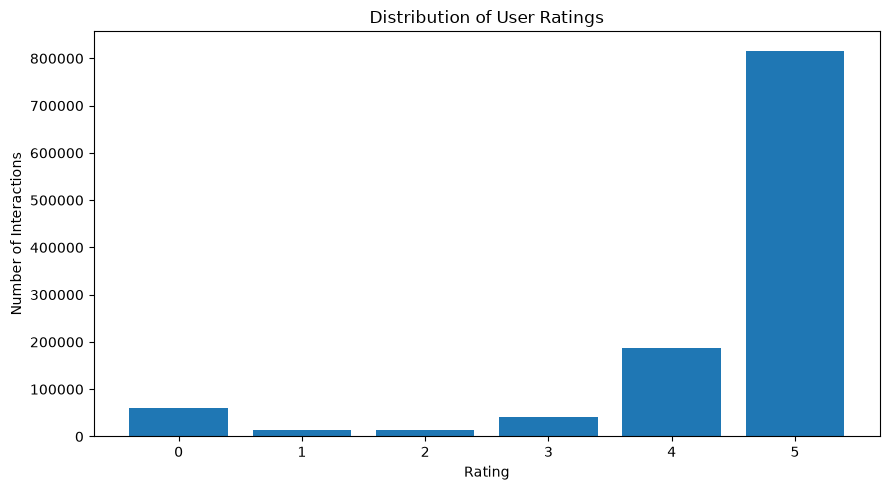

In [13]:

# Create a bar chart for rating distribution

plt.figure(figsize=(9, 5))

plt.bar(
    rating_distribution.index,
    rating_distribution["Rating Count"]
)

plt.title("Distribution of User Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Interactions")
plt.xticks(rating_distribution.index)

plt.tight_layout()
plt.show()



## 15. Overall Conclusion

The initial exploration of the Food.com datasets provided an understanding of their structure, data quality, and important characteristics.

The Recipes dataset contains 231,637 records and 12 columns, while the User Interactions dataset contains 1,132,367 records and 5 columns.

The analysis identified a small number of missing values and no exact duplicate records.

The rating distribution revealed that 72.09% of interactions received a rating of 5, demonstrating a strong concentration of positive ratings.

The numerical summaries also identified extreme values in cooking time that require further investigation.

These findings provide the foundation for the next stages of the project, including data cleaning, preprocessing, exploratory data analysis, and recipe ranking.

The original datasets remain unchanged throughout this exploration.
